# EuroSAT: decision fusion

Read [the project guide](README.md) before execution. Outputs below are historical, not rerun after portability edits. Source cell numbers in the guide are zero-based and correspond to `source-NNN` cell IDs. Training cells can be expensive.


In [1]:
import os

In [2]:

DATASET = r"data/EuroSAT"

# Get only folder names (ignore files like .json)
LABELS = [d for d in os.listdir(DATASET) if os.path.isdir(os.path.join(DATASET, d))]

print(" Found Labels:")
print(LABELS)

 Found Labels:
['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


In [3]:
import tensorflow as tf
import numpy as np
import cv2
import matplotlib.pyplot as plt
import os


In [4]:
class_names = ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 
               'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 
               'Residential', 'River', 'SeaLake'] 

num_classes = len(class_names)
print("Using class names:", class_names)


Using class names: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


In [5]:

from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout, BatchNormalization
from tensorflow.keras.models import Sequential

def build_transfer_model(base_model, num_classes):
    model = Sequential()
    model.add(base_model)
    model.add(GlobalAveragePooling2D())
    model.add(Dense(256, activation='relu'))
    model.add(BatchNormalization())
    model.add(Dropout(0.3))
    model.add(Dense(num_classes, activation='softmax'))
    return model

# IMPORTANT: weights=None to avoid loading imagenet during inference
base_model = tf.keras.applications.MobileNetV2(
    weights=None,
    include_top=False,
    input_shape=(128, 128, 3)
)

mobilenet_model = build_transfer_model(base_model, num_classes)

# Load the weights you saved after training
mobilenet_model.load_weights("mobilenet_best_weights.weights.h5")

print("MobileNetV2 weights loaded successfully!")


MobileNetV2 weights loaded successfully!


In [6]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam

def create_cnn_model():
    model = Sequential([
        Conv2D(32, (3,3), activation='relu', input_shape=(64, 64, 3)),
        MaxPooling2D(2,2),

        Conv2D(64, (3,3), activation='relu'),
        MaxPooling2D(2,2),

        Conv2D(128, (3,3), activation='relu'),
        MaxPooling2D(2,2),

        Flatten(),
        Dense(128, activation='relu'),
        Dropout(0.5),
        Dense(num_classes, activation='softmax')
    ])

    model.compile(
        optimizer=Adam(learning_rate=8e-4),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

cnn_model = create_cnn_model()

# Load the weights you saved after training
cnn_model.load_weights("dropout_weights/dropout_fold_1.weights.h5")

print(" loaded successfully!")




 loaded successfully!


<local-eurosat>\tfenv\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
<local-eurosat>\tfenv\lib\site-packages\keras\src\saving\saving_lib.py:802: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 22 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [ ]:
import cv2
import numpy as np
import joblib
from scipy.stats import skew

# 1) دالة Color Moments
def extract_color_moments(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    chans = cv2.split(hsv)
    features = []
    for ch in chans:
        ch_flat = ch.reshape(-1)
        features.append(ch_flat.mean())
        features.append(ch_flat.std())
        features.append(skew(ch_flat))
    return np.array(features, dtype=np.float32)

# 2) تحميل الـ scaler المحفوظ
cm_scaler = joblib.load("cm_scaler.pkl")
print("Loaded cm_scaler with n_features =", cm_scaler.n_features_in_)


Loaded cm_scaler with n_features = 9


In [8]:
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.models import Sequential

def build_ann(input_dim, output_dim, lr=1e-3):
    model = Sequential([
        Dense(256, activation='relu', input_dim=input_dim),
        BatchNormalization(),
        Dropout(0.3),

        Dense(128, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),

        Dense(output_dim, activation='softmax')
    ])
    model.compile(
        optimizer=Adam(learning_rate=lr),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model


tmp_img_path = os.path.join(DATASET, class_names[0], os.listdir(os.path.join(DATASET, class_names[0]))[0])
tmp_img = cv2.imread(tmp_img_path)
tmp_img = cv2.resize(tmp_img, (64, 64))
tmp_cm = extract_color_moments(tmp_img)   # نفس الفنكشن اللي استخدمتيه بالتدريب
input_dim = len(tmp_cm)

ann_model = build_ann(input_dim=input_dim, output_dim=num_classes)
ann_model.load_weights("ann_color_best_weights.weights.h5")
print("ANN + CM weights loaded successfully!")


ANN + CM weights loaded successfully!


<local-eurosat>\tfenv\lib\site-packages\keras\src\layers\core\dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
# =========================================================
# 5) تحضير الصور لكل موديل + CM للـ ANN
# =========================================================
def prepare_inputs_for_models(img_path):
    # MobileNetV2 (128x128)
    img_m = cv2.imread(img_path)
    img_m = cv2.resize(img_m, (128, 128))
    img_m = img_m.astype("float32") / 255.0
    img_m = np.expand_dims(img_m, axis=0)

    # CNN (64x64)
    img_c = cv2.imread(img_path)
    img_c = cv2.resize(img_c, (64, 64))
    img_c = img_c.astype("float32") / 255.0
    img_c = np.expand_dims(img_c, axis=0)

    img_a = cv2.imread(img_path)
    img_a = cv2.resize(img_a, (64, 64))
    cm_feat = extract_color_moments(img_a)          
    
    # نطبّق نفس الـ scaler المستخدم في التدريب
    cm_feat_scaled = cm_scaler.transform([cm_feat]) 

    return img_m, img_c, cm_feat_scaled


In [10]:

def predict_all_models(img_path, verbose=True):
    img_m, img_c, cm_feat = prepare_inputs_for_models(img_path)

    # --- Probabilities ---
    pred_m = mobilenet_model.predict(img_m, verbose=0)[0]
    pred_c = cnn_model.predict(img_c, verbose=0)[0]
    pred_a = ann_model.predict(cm_feat, verbose=0)[0]

    # --- Class indices ---
    m_class = np.argmax(pred_m)
    c_class = np.argmax(pred_c)
    a_class = np.argmax(pred_a)

    # --- Majority Voting ---
    votes = np.bincount([m_class, c_class, a_class], minlength=num_classes)
    vote_class = np.argmax(votes)

    # --- Average Probabilities Fusion ---
    avg_probs = (pred_m + pred_c + pred_a) / 3.0
    avg_class = np.argmax(avg_probs)

    if votes[vote_class] == 1 and vote_class != avg_class:
        final_class = avg_class
        fusion_strategy = "average_probs (tie break)"
    else:
        final_class = vote_class
        fusion_strategy = "majority_vote"

    if verbose:
        print("\n=== Per-Model Predictions ===")
        print(f"MobileNetV2 -> {class_names[m_class]} (conf = {pred_m[m_class]:.4f})")
        print(f"CNN         -> {class_names[c_class]} (conf = {pred_c[c_class]:.4f})")
        print(f"ANN + CM    -> {class_names[a_class]} (conf = {pred_a[a_class]:.4f})")

        print("\n=== Raw Probability Vectors ===")
        print("MobileNetV2 probs:\n", pred_m)
        print("CNN probs:\n", pred_c)
        print("ANN + CM probs:\n", pred_a)

        print("\n=== Fusion (Decision Level) ===")
        print("Average fused probs:\n", avg_probs)
        print("Majority vote class:", class_names[vote_class])
        print("Average probs class:", class_names[avg_class])
        print(f"Final Fusion Prediction: {class_names[final_class]}  (strategy = {fusion_strategy})")

    return {
        "pred_m_probs": pred_m,
        "pred_c_probs": pred_c,
        "pred_a_probs": pred_a,
        "avg_probs": avg_probs,
        "m_class": m_class,
        "c_class": c_class,
        "a_class": a_class,
        "vote_class": vote_class,
        "avg_class": avg_class,
        "final_class": final_class,
        "final_label": class_names[final_class],
        "votes": votes
    }

def late_fusion_predict(img_path):
    """دالة بسيطة ترجع الليبل النهائي وتعرض الصورة."""
    result = predict_all_models(img_path, verbose=True)
    final_label = result["final_label"]

    img = cv2.imread(img_path)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(final_label)
    plt.axis("off")
    plt.show()

    return final_label



=== Per-Model Predictions ===
MobileNetV2 -> Industrial (conf = 0.8001)
CNN         -> Industrial (conf = 0.6544)
ANN + CM    -> River (conf = 0.3173)

=== Raw Probability Vectors ===
MobileNetV2 probs:
 [0.04114968 0.00260441 0.0044682  0.03313015 0.8000888  0.02607203
 0.01258962 0.04606809 0.0104604  0.02336861]
CNN probs:
 [4.3922564e-04 2.8280279e-05 4.5637265e-02 1.1917510e-01 6.5439719e-01
 1.0402471e-04 1.7102232e-02 9.6107878e-02 6.6900507e-02 1.0829761e-04]
ANN + CM probs:
 [6.2537447e-02 2.1338863e-04 3.6306534e-05 2.1850671e-01 7.8385539e-02
 1.2521933e-05 4.6373654e-05 5.7361713e-03 3.1727311e-01 3.1725246e-01]

=== Fusion (Decision Level) ===
Average fused probs:
 [0.03470878 0.00094869 0.01671392 0.12360398 0.5109572  0.00872952
 0.00991274 0.04930405 0.13154466 0.11357645]
Majority vote class: Industrial
Average probs class: Industrial
Final Fusion Prediction: Industrial  (strategy = majority_vote)


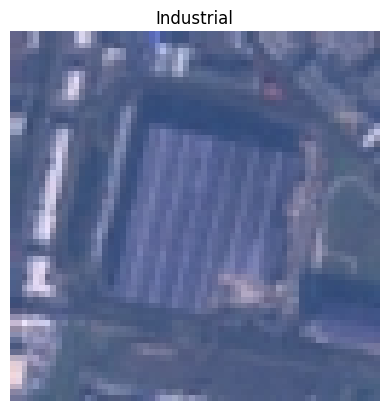

Final fused prediction: Industrial


In [11]:
img_path = r"data/EuroSAT/Industrial/Industrial_100.jpg"
result_label = late_fusion_predict(img_path)
print("Final fused prediction:", result_label)


In [12]:
import os
import random
import numpy as np
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

def evaluate_late_fusion_sample(dataset_dir, max_images=500):
    """
    تقييم الفيوجن + كل موديل على عيّنة محددة من الصور
    عشان يكون أسرع بكثير من كل الداتا.
    """
    print("Starting sampled evaluation on:", dataset_dir)
    print("Max images to evaluate:", max_images)

    valid_ext = (".jpg", ".jpeg", ".png", ".tif", ".tiff")

    # --------- 1) جمع كل الصور مع اللايبل حقها ---------
    all_samples = []   # list of (img_path, class_idx)

    for class_idx, class_name in enumerate(class_names):
        class_folder = os.path.join(dataset_dir, class_name)
        if not os.path.isdir(class_folder):
            continue

        for fname in os.listdir(class_folder):
            if fname.lower().endswith(valid_ext):
                img_path = os.path.join(class_folder, fname)
                all_samples.append((img_path, class_idx))

    print("Total images found in dataset:", len(all_samples))

    if len(all_samples) == 0:
        print("⚠️ No images found. Check dataset path and class_names.")
        return None

    # --------- 2) اختيار عيّنة عشوائية ---------
    if len(all_samples) > max_images:
        all_samples = random.sample(all_samples, max_images)

    print("Evaluating on", len(all_samples), "images (sampled).")

    # --------- 3) تخزين اللايبلات والتوقعات ---------
    y_true = []
    y_pred_m = []
    y_pred_c = []
    y_pred_a = []
    y_pred_vote = []
    y_pred_avg = []

    for idx, (img_path, class_idx) in enumerate(all_samples, 1):
        res = predict_all_models(img_path, verbose=False)

        y_true.append(class_idx)
        y_pred_m.append(res["m_class"])
        y_pred_c.append(res["c_class"])
        y_pred_a.append(res["a_class"])
        y_pred_vote.append(res["vote_class"])
        y_pred_avg.append(res["avg_class"])

        if idx % 50 == 0:
            print(f"  Processed {idx}/{len(all_samples)} images...")

    y_true = np.array(y_true)

    # --------- 4) حساب المقاييس ---------
    print("\n========== Accuracy per model (sample) ==========")
    acc_m = accuracy_score(y_true, y_pred_m)
    acc_c = accuracy_score(y_true, y_pred_c)
    acc_a = accuracy_score(y_true, y_pred_a)
    acc_vote = accuracy_score(y_true, y_pred_vote)
    acc_avg = accuracy_score(y_true, y_pred_avg)

    print("MobileNetV2 Accuracy :", acc_m)
    print("CNN Accuracy         :", acc_c)
    print("ANN + CM Accuracy    :", acc_a)
    print("Fusion (Majority)    :", acc_vote)
    print("Fusion (Average)     :", acc_avg)

    print("\n========== Classification Report (Fusion - Majority Vote) ==========")
    cls_report = classification_report(y_true, y_pred_vote, target_names=class_names)
    print(cls_report)

    cm = confusion_matrix(y_true, y_pred_vote)
    print("\nConfusion Matrix (Fusion - Majority Vote):")
    print(cm)

    return {
        "acc_mobilenet": acc_m,
        "acc_cnn": acc_c,
        "acc_ann_cm": acc_a,
        "acc_fusion_vote": acc_vote,
        "acc_fusion_avg": acc_avg,
        "classification_report": cls_report,
        "confusion_matrix": cm,
        "n_images": len(all_samples)
    }


In [13]:
results = evaluate_late_fusion_sample(DATASET, max_images=500)


Starting sampled evaluation on: <local-eurosat>\eurosat_data\EuroSAT
Max images to evaluate: 500
Total images found in dataset: 27000
Evaluating on 500 images (sampled).
  Processed 50/500 images...
  Processed 100/500 images...
  Processed 150/500 images...
  Processed 200/500 images...
  Processed 250/500 images...
  Processed 300/500 images...
  Processed 350/500 images...
  Processed 400/500 images...
  Processed 450/500 images...
  Processed 500/500 images...

========== Accuracy per model (sample) ==========
MobileNetV2 Accuracy : 0.52
CNN Accuracy         : 0.914
ANN + CM Accuracy    : 0.234
Fusion (Majority)    : 0.59
Fusion (Average)     : 0.678

========== Classification Report (Fusion - Majority Vote) ==========
                      precision    recall  f1-score   support

          AnnualCrop       0.31      0.97      0.47        70
              Forest       0.97      0.91      0.94        65
HerbaceousVegetation       0.43      0.20      0.28        59
             Highw

<local-eurosat>\tfenv\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
<local-eurosat>\tfenv\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
<local-eurosat>\tfenv\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
